## Race Metadata

| Field | Value |
|---|---|
| Season | 2024 |
| Round | 16 |
| Grand Prix | Italian Grand Prix |
| Session | Race |
| Circuit | Autodromo Nazionale Monza |
| Location | Monza, Italy |
| Circuit length | 5.793 km |
| Race distance | 306.72 km |
| Total laps | 53 |
| Track direction | Clockwise |
| Target driver | Charles Leclerc (`LEC - 16`), Ferrari |

### Case Study Goal

This notebook uses the 2024 Italian Grand Prix as the first case study for the F1 Pit Strategy Optimizer.

The initial objective is to inspect Charles Leclerc's lap-level data, tyre stints, pit-stop timing, track conditions, and race position changes. Later phases will use this information to compare alternative one-stop and two-stop strategies.

### Why Monza 2024?

The 2024 Italian Grand Prix is a useful strategy case because Charles Leclerc won with a one-stop strategy while McLaren used two-stop approaches. This makes the race suitable for analysing tyre degradation, pit-stop loss, and strategy trade-offs.

**Source:** [Formula 1 — Monza circuit guide](https://www.formula1.com/en/latest/article/circuit-guide-everything-you-need-to-know-about-the-autodromo-nazionale-monza.51PKqBRlxNs0fzLWQzsnd0)

Import FastF1

In [1]:
import pandas as pd
import fastf1
from pathlib import Path


project_root = Path.cwd().parent

cache_dir = project_root / "data" / "cache" / "fastf1"

cache_dir.mkdir(parents=True, exist_ok=True)

fastf1.Cache.enable_cache(str(cache_dir))

print(f"Project root: {project_root}")
print(f"Cache path: {cache_dir.resolve()}")
print(f"Cache exists: {cache_dir.exists()}")

#time format(min:sec.ms)
def format_time(value):
    if pd.isna(value):
        return None

    total_ms = round(value.total_seconds() * 1000)

    minutes, remainder = divmod(total_ms, 60_000)
    seconds, milliseconds = divmod(remainder, 1_000)

    return f"{minutes}:{seconds:02d}.{milliseconds:03d}"


Project root: c:\Users\umutnevzat.kahraman\Desktop\f1-pit-strategy-optimizer
Cache path: C:\Users\umutnevzat.kahraman\Desktop\f1-pit-strategy-optimizer\data\cache\fastf1
Cache exists: True


Get the race(2024 Italian GP)

In [2]:
session = fastf1.get_session(2024, "Italian Grand Prix", "R") 

session.load(
    telemetry=False,
    weather=True,
    messages=False
)

session.event

core           INFO 	Loading data for Italian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for weather_data
core           INFO 	Finished loading data for 20 drivers: ['16', '81', '4', '55', '44', '1', '63', '11', '23', '20', '14', '43', '3', '31', '10', '77', '27', '24', '18', '22']


RoundNumber                                                   16
Country                                                    Italy
Location                                                   Monza
OfficialEventName    FORMULA 1 PIRELLI GRAN PREMIO D’ITALIA 2024
EventDate                                    2024-09-01 00:00:00
EventName                                     Italian Grand Prix
EventFormat                                         conventional
Session1                                              Practice 1
Session1Date                           2024-08-30 13:30:00+02:00
Session1DateUtc                              2024-08-30 11:30:00
Session2                                              Practice 2
Session2Date                           2024-08-30 17:00:00+02:00
Session2DateUtc                              2024-08-30 15:00:00
Session3                                              Practice 3
Session3Date                           2024-08-31 12:30:00+02:00
Session3DateUtc          

Get the columns for the race

In [3]:
print("Result Columns:")
print(session.results.columns.tolist())

print("\nLap Columns:")
print(session.laps.columns.tolist())

Result Columns:
['DriverNumber', 'BroadcastName', 'Abbreviation', 'DriverId', 'TeamName', 'TeamColor', 'TeamId', 'FirstName', 'LastName', 'FullName', 'HeadshotUrl', 'CountryCode', 'Position', 'ClassifiedPosition', 'GridPosition', 'Q1', 'Q2', 'Q3', 'Time', 'Status', 'Points', 'Laps']

Lap Columns:
['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate']


Race History

In [4]:
results_summary = session.results[
    ["Abbreviation", "TeamName", "GridPosition", "Position", "Status"]
]

results_summary

,Abbreviation,TeamName,GridPosition,Position,Status
16,LEC,Ferrari,4.0,1.0,Finished
81,PIA,McLaren,2.0,2.0,Finished
4,NOR,McLaren,1.0,3.0,Finished
55,SAI,Ferrari,5.0,4.0,Finished
44,HAM,Mercedes,6.0,5.0,Finished
1,VER,Red Bull Racing,7.0,6.0,Finished
63,RUS,Mercedes,3.0,7.0,Finished
11,PER,Red Bull Racing,8.0,8.0,Finished
23,ALB,Williams,9.0,9.0,Finished
20,MAG,Haas F1 Team,13.0,10.0,Finished


Leclerc(LEC, 16) Race History

In [5]:
leclerc_laps = session.laps.pick_drivers("LEC")[
    ["Stint", "LapNumber", "LapTime", "Position", "Compound", "TyreLife", "PitInTime", "PitOutTime", "TrackStatus", "IsAccurate"]
]

time_columns = [
    "LapTime",
    "PitInTime",
    "PitOutTime"
]

for column in time_columns:
    leclerc_laps[column] = leclerc_laps[column].apply(format_time)

leclerc_laps

,Stint,LapNumber,LapTime,Position,Compound,TyreLife,PitInTime,PitOutTime,TrackStatus,IsAccurate
0,1.0,1.0,1:28.179,2.0,MEDIUM,1.0,None,None,1,False
1,1.0,2.0,1:25.396,2.0,MEDIUM,2.0,None,None,1,True
2,1.0,3.0,1:25.179,2.0,MEDIUM,3.0,None,None,1,True
3,1.0,4.0,1:24.810,2.0,MEDIUM,4.0,None,None,1,True
4,1.0,5.0,1:24.603,2.0,MEDIUM,5.0,None,None,1,True
5,1.0,6.0,1:24.663,2.0,MEDIUM,6.0,None,None,1,True
6,1.0,7.0,1:24.434,2.0,MEDIUM,7.0,None,None,1,True
7,1.0,8.0,1:24.569,2.0,MEDIUM,8.0,None,None,1,True
8,1.0,9.0,1:24.362,2.0,MEDIUM,9.0,None,None,1,True
9,1.0,10.0,1:24.432,2.0,MEDIUM,10.0,None,None,1,True


In [6]:
print(session.total_laps)

53


Starting Grid Positions

In [7]:
starting_grid = results_summary.sort_values(
    by="GridPosition",
    ascending=True
)

starting_grid

,Abbreviation,TeamName,GridPosition,Position,Status
4,NOR,McLaren,1.0,3.0,Finished
81,PIA,McLaren,2.0,2.0,Finished
63,RUS,Mercedes,3.0,7.0,Finished
16,LEC,Ferrari,4.0,1.0,Finished
55,SAI,Ferrari,5.0,4.0,Finished
44,HAM,Mercedes,6.0,5.0,Finished
1,VER,Red Bull Racing,7.0,6.0,Finished
11,PER,Red Bull Racing,8.0,8.0,Finished
23,ALB,Williams,9.0,9.0,Finished
27,HUL,Haas F1 Team,10.0,17.0,Lapped


Lap&Sector Times for All Drivers

In [8]:
lap_time_columns = [
    "Driver",
    "LapNumber",
    "LapTime",
    "Sector1Time",
    "Sector2Time",
    "Sector3Time",
    "Position",
    "IsAccurate"
]
race_laps = session.laps[lap_time_columns].copy()

race_laps

,Driver,LapNumber,LapTime,Sector1Time,Sector2Time,Sector3Time,Position,IsAccurate
0,LEC,1.0,0 days 00:01:28.179000,NaT,0 days 00:00:29.989000,0 days 00:00:28.398000,2.0,False
1,LEC,2.0,0 days 00:01:25.396000,0 days 00:00:27.707000,0 days 00:00:29.265000,0 days 00:00:28.424000,2.0,True
2,LEC,3.0,0 days 00:01:25.179000,0 days 00:00:27.679000,0 days 00:00:29.001000,0 days 00:00:28.499000,2.0,True
3,LEC,4.0,0 days 00:01:24.810000,0 days 00:00:27.653000,0 days 00:00:28.883000,0 days 00:00:28.274000,2.0,True
4,LEC,5.0,0 days 00:01:24.603000,0 days 00:00:27.630000,0 days 00:00:28.790000,0 days 00:00:28.183000,2.0,True
...,...,...,...,...,...,...,...,...
1003,TSU,3.0,0 days 00:01:26.665000,0 days 00:00:27.756000,0 days 00:00:29.819000,0 days 00:00:29.090000,15.0,True
1004,TSU,4.0,0 days 00:01:26.198000,0 days 00:00:27.631000,0 days 00:00:29.689000,0 days 00:00:28.878000,15.0,True
1005,TSU,5.0,0 days 00:01:32.241000,0 days 00:00:28.736000,0 days 00:00:32.722000,0 days 00:00:30.783000,19.0,True
1006,TSU,6.0,0 days 00:01:28.473000,0 days 00:00:28.426000,0 days 00:00:30.441000,0 days 00:00:29.606000,19.0,True


Strategy Informations for All Drivers

In [9]:
strategy_columns = [
    "Driver",
    "LapNumber",
    "Position",
    "Stint",
    "Compound",
    "TyreLife",
    "PitInTime",
    "PitOutTime",
    "TrackStatus",
    "IsAccurate"
]
strategy_info = session.laps[strategy_columns].copy()

strategy_info

,Driver,LapNumber,Position,Stint,Compound,TyreLife,PitInTime,PitOutTime,TrackStatus,IsAccurate
0,LEC,1.0,2.0,1.0,MEDIUM,1.0,NaT,NaT,1,False
1,LEC,2.0,2.0,1.0,MEDIUM,2.0,NaT,NaT,1,True
2,LEC,3.0,2.0,1.0,MEDIUM,3.0,NaT,NaT,1,True
3,LEC,4.0,2.0,1.0,MEDIUM,4.0,NaT,NaT,1,True
4,LEC,5.0,2.0,1.0,MEDIUM,5.0,NaT,NaT,1,True
...,...,...,...,...,...,...,...,...,...,...
1003,TSU,3.0,15.0,1.0,HARD,4.0,NaT,NaT,1,True
1004,TSU,4.0,15.0,1.0,HARD,5.0,NaT,NaT,1,True
1005,TSU,5.0,19.0,1.0,HARD,6.0,NaT,NaT,1,True
1006,TSU,6.0,19.0,1.0,HARD,7.0,NaT,NaT,1,True


All-Grid Strategy


In [10]:
strategy_columns = [
    "Driver",
    "LapNumber",
    "Position",
    "Stint",
    "Compound",
    "TyreLife",
    "LapTime",
    "PitInTime",
    "PitOutTime",
    "TrackStatus",
    "IsAccurate"
]

race_strategy_laps = session.laps[strategy_columns].copy()

race_strategy_laps.head()

,Driver,LapNumber,Position,Stint,Compound,TyreLife,LapTime,PitInTime,PitOutTime,TrackStatus,IsAccurate
0,LEC,1.0,2.0,1.0,MEDIUM,1.0,0 days 00:01:28.179000,NaT,NaT,1,False
1,LEC,2.0,2.0,1.0,MEDIUM,2.0,0 days 00:01:25.396000,NaT,NaT,1,True
2,LEC,3.0,2.0,1.0,MEDIUM,3.0,0 days 00:01:25.179000,NaT,NaT,1,True
3,LEC,4.0,2.0,1.0,MEDIUM,4.0,0 days 00:01:24.810000,NaT,NaT,1,True
4,LEC,5.0,2.0,1.0,MEDIUM,5.0,0 days 00:01:24.603000,NaT,NaT,1,True


Pit Laps


In [11]:
race_strategy_laps = race_strategy_laps.copy()

race_strategy_laps["IsPitInLap"] = race_strategy_laps["PitInTime"].notna()
race_strategy_laps["IsPitOutLap"] = race_strategy_laps["PitOutTime"].notna()


race_strategy_laps["IsPitRelatedLap"] = (race_strategy_laps["IsPitInLap"] | race_strategy_laps["IsPitOutLap"])

pit_laps = race_strategy_laps[race_strategy_laps["IsPitRelatedLap"]].sort_values(["Driver", "LapNumber"])

pit_laps

,Driver,LapNumber,Position,Stint,Compound,TyreLife,LapTime,PitInTime,PitOutTime,TrackStatus,IsAccurate,IsPitInLap,IsPitOutLap,IsPitRelatedLap
440,ALB,17.0,7.0,1.0,MEDIUM,17.0,0 days 00:01:31.436000,0 days 01:20:21.362000,NaT,1,False,True,False,True
441,ALB,18.0,13.0,2.0,HARD,1.0,0 days 00:01:46.033000,NaT,0 days 01:20:46.162000,1,False,False,True,True
541,ALO,12.0,11.0,1.0,MEDIUM,13.0,0 days 00:01:29.740000,0 days 01:13:10.512000,NaT,1,False,True,False,True
542,ALO,13.0,15.0,2.0,HARD,2.0,0 days 00:01:45.594000,NaT,0 days 01:13:35.387000,1,False,False,True,True
564,ALO,35.0,9.0,2.0,HARD,24.0,0 days 00:01:29.799000,0 days 01:46:11.502000,NaT,1,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
287,VER,23.0,8.0,2.0,HARD,1.0,0 days 00:01:47.839000,NaT,0 days 01:27:41.632000,1,False,False,True,True
305,VER,41.0,5.0,2.0,HARD,19.0,0 days 00:01:28.738000,0 days 01:54:11.181000,NaT,1,False,True,False,True
306,VER,42.0,6.0,3.0,MEDIUM,1.0,0 days 00:01:44.090000,NaT,0 days 01:54:35.133000,1,False,False,True,True
911,ZHO,15.0,13.0,1.0,MEDIUM,16.0,0 days 00:01:32.048000,0 days 01:17:44.783000,NaT,1,False,True,False,True


Track Status

In [12]:
race_strategy_laps["TrackStatus"].value_counts(dropna=False)

TrackStatus
1    1008
Name: count, dtype: int64

Safety Car & Yellow Flag Laps

In [13]:
race_strategy_laps["HasSafetyCar"] = race_strategy_laps[
    "TrackStatus"
].str.contains("4", na=False)

race_strategy_laps["HasVSC"] = race_strategy_laps[
    "TrackStatus"
].str.contains("6", na=False)

race_strategy_laps["HasYellowFlag"] = race_strategy_laps[
    "TrackStatus"
].str.contains("2", na=False)

Race Weather Data

In [14]:
weather_columns = [
    "Time",
    "AirTemp",
    "Humidity",
    "Pressure",
    "Rainfall",
    "TrackTemp",
    "WindDirection",
    "WindSpeed"
]

weather_data = session.weather_data[weather_columns].copy()

weather_data

,Time,AirTemp,Humidity,Pressure,Rainfall,TrackTemp,WindDirection,WindSpeed
0,0 days 00:00:26.141000,33.2,38.0,993.8,False,52.1,318,0.7
1,0 days 00:01:26.139000,33.2,37.0,993.9,False,52.1,207,1.0
2,0 days 00:02:26.141000,33.2,37.0,993.9,False,52.8,230,1.3
3,0 days 00:03:26.146000,33.2,36.0,993.8,False,52.8,200,0.7
4,0 days 00:04:26.151000,33.3,36.0,993.8,False,52.8,182,0.8
...,...,...,...,...,...,...,...,...
128,0 days 02:08:26.615000,32.2,33.0,992.7,False,43.9,213,1.4
129,0 days 02:09:26.629000,32.2,32.0,992.9,False,43.8,207,1.7
130,0 days 02:10:26.648000,32.2,32.0,992.8,False,43.8,218,1.8
131,0 days 02:11:26.663000,32.2,32.0,992.7,False,43.6,220,1.6


In [15]:
weather_display = weather_data.copy()


weather_display["Rainfall"] = weather_display["Rainfall"].map(
    {False: "No", True: "Yes"}
)

weather_display.head().style.format(
    {
        "AirTemp": "{:.1f} °C",
        "TrackTemp": "{:.1f} °C",
        "Humidity": "{:.0f}%",
        "Pressure": "{:.1f} mbar",
        "WindDirection": "{:.0f}°",
        "WindSpeed": "{:.1f} m/s",
    }
)

,Time,AirTemp,Humidity,Pressure,Rainfall,TrackTemp,WindDirection,WindSpeed
0,0 days 00:00:26.141000,33.2 °C,38%,993.8 mbar,No,52.1 °C,318°,0.7 m/s
1,0 days 00:01:26.139000,33.2 °C,37%,993.9 mbar,No,52.1 °C,207°,1.0 m/s
2,0 days 00:02:26.141000,33.2 °C,37%,993.9 mbar,No,52.8 °C,230°,1.3 m/s
3,0 days 00:03:26.146000,33.2 °C,36%,993.8 mbar,No,52.8 °C,200°,0.7 m/s
4,0 days 00:04:26.151000,33.3 °C,36%,993.8 mbar,No,52.8 °C,182°,0.8 m/s


In [16]:
starting_grid["Status"].value_counts(dropna=False)

Status
Finished    13
Lapped       6
Retired      1
Name: count, dtype: int64

In [17]:
race_classification = starting_grid.copy()

race_classification["RaceClassification"] = race_classification[
    "Status"
].replace(
    {
        "Retired": "DNF"
    }
)

race_classification["IncludeInBaselineSimulation"] = (
    race_classification["RaceClassification"] != "DNF"
)

race_classification

,Abbreviation,TeamName,GridPosition,Position,Status,RaceClassification,IncludeInBaselineSimulation
4,NOR,McLaren,1.0,3.0,Finished,Finished,True
81,PIA,McLaren,2.0,2.0,Finished,Finished,True
63,RUS,Mercedes,3.0,7.0,Finished,Finished,True
16,LEC,Ferrari,4.0,1.0,Finished,Finished,True
55,SAI,Ferrari,5.0,4.0,Finished,Finished,True
44,HAM,Mercedes,6.0,5.0,Finished,Finished,True
1,VER,Red Bull Racing,7.0,6.0,Finished,Finished,True
11,PER,Red Bull Racing,8.0,8.0,Finished,Finished,True
23,ALB,Williams,9.0,9.0,Finished,Finished,True
27,HUL,Haas F1 Team,10.0,17.0,Lapped,Lapped,True


In [18]:
from pathlib import Path

project_root = Path.cwd().parent

In [19]:
raw_dir = project_root / "data" / "raw"

raw_dir.mkdir(parents=True, exist_ok=True)

session.laps.to_csv(
    raw_dir / "monza_2024_race_laps.csv",
    index=False
)

session.results.to_csv(
    raw_dir / "monza_2024_race_results.csv",
    index=False
)

session.weather_data.to_csv(
    raw_dir / "monza_2024_weather.csv",
    index=False
)

session.event.to_json(
    raw_dir / "monza_2024_event_metadata.json",
    indent=2,
    date_format="iso"
)

print("Saved raw files:")
for file_path in sorted(raw_dir.iterdir()):
    print("-", file_path.name)

Saved raw files:
- monza_2024_event_metadata.json
- monza_2024_race_laps.csv
- monza_2024_race_results.csv
- monza_2024_weather.csv


Missing Value Test

In [20]:
missing_summary = (
    race_strategy_laps
    .isna()
    .sum()
    .rename("MissingCount")
    .to_frame()
)

missing_summary["MissingPercentage"] = (
    missing_summary["MissingCount"]
    / len(race_strategy_laps)
    * 100
).round(2)

missing_summary = missing_summary.sort_values(
    by="MissingCount",
    ascending=False
)

missing_summary

,MissingCount,MissingPercentage
PitOutTime,978,97.02
PitInTime,977,96.92
Driver,0,0.00
LapNumber,0,0.00
Position,0,0.00
Compound,0,0.00
Stint,0,0.00
LapTime,0,0.00
TyreLife,0,0.00
TrackStatus,0,0.00


In [21]:
weather_missing = (
    weather_data
    .isna()
    .sum()
    .rename("MissingCount")
    .to_frame()
)

weather_missing = weather_missing.sort_values(
    by="MissingCount",
    ascending=False
)

weather_missing

,MissingCount
Time,0
AirTemp,0
Humidity,0
Pressure,0
Rainfall,0
TrackTemp,0
WindDirection,0
WindSpeed,0


*Missing values in `PitInTime` and `PitOutTime` are expected. These columns are only populated for laps associated with a pit-lane entry or exit. No missing values except those expected ones.* 

Negative-Zero-Unrealistic Lap Times Test

In [22]:
lap_quality = race_strategy_laps[
    ["Driver", "LapNumber", "LapTime", "IsPitRelatedLap"]
].copy()

lap_quality["LapTimeSeconds"] = (
    pd.to_timedelta(lap_quality["LapTime"])
    .dt.total_seconds()
)

lap_quality.head()

,Driver,LapNumber,LapTime,IsPitRelatedLap,LapTimeSeconds
0,LEC,1.0,0 days 00:01:28.179000,False,88.179
1,LEC,2.0,0 days 00:01:25.396000,False,85.396
2,LEC,3.0,0 days 00:01:25.179000,False,85.179
3,LEC,4.0,0 days 00:01:24.810000,False,84.810
4,LEC,5.0,0 days 00:01:24.603000,False,84.603


In [23]:
invalid_laps = lap_quality[
    lap_quality["LapTimeSeconds"] <= 0
]

print(f"Invalid lap count: {len(invalid_laps)}")

Invalid lap count: 0


In [24]:
MIN_REALISTIC_LAP_SECONDS = 50
MAX_REALISTIC_LAP_SECONDS = 130

unrealistic_laps = lap_quality[
    lap_quality["LapTimeSeconds"].notna()
    & ~lap_quality["LapTimeSeconds"].between(
        MIN_REALISTIC_LAP_SECONDS,
        MAX_REALISTIC_LAP_SECONDS
    )
]

print(f"Unrealistic lap count: {len(unrealistic_laps)}")

Unrealistic lap count: 0


*Lap times were converted from `Timedelta` values to seconds for validation.*
*The dataset was checked for: negative lap times, zero lap times, missing lap times, lap times outside the initial Monza-specific range of 50 to 180 seconds. No unrealistic-invalid lap times found.*

Pit Related and Normal Lap Distribution Tables

In [25]:
lap_time_distribution_data = race_strategy_laps[
    ["Driver", "LapNumber", "LapTime", "IsPitRelatedLap"]
].copy()

lap_time_distribution_data["LapTimeSeconds"] = (
    pd.to_timedelta(lap_time_distribution_data["LapTime"])
    .dt.total_seconds()
)

lap_time_distribution_data = lap_time_distribution_data[
    lap_time_distribution_data["LapTimeSeconds"].notna()
    & (lap_time_distribution_data["LapTimeSeconds"] > 0)
]

pit_laps = lap_time_distribution_data[
    lap_time_distribution_data["IsPitRelatedLap"]
]

normal_laps = lap_time_distribution_data[
    ~lap_time_distribution_data["IsPitRelatedLap"]
]

print(f"Pit-related laps: {len(pit_laps)}")
print(f"Normal laps: {len(normal_laps)}")



Pit-related laps: 61
Normal laps: 947


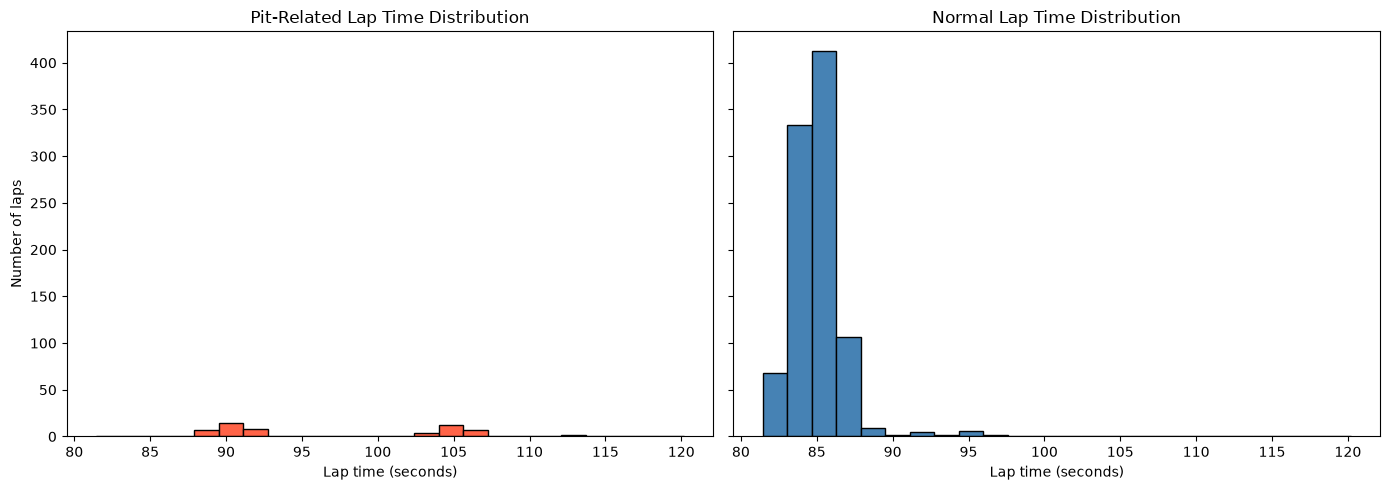

In [26]:
import matplotlib.pyplot as plt
import numpy as np

all_times = lap_time_distribution_data["LapTimeSeconds"]

bins = np.linspace(
    all_times.min(),
    all_times.max(),
    25
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharey=True
)

axes[0].hist(
    pit_laps["LapTimeSeconds"],
    bins=bins,
    color="tomato",
    edgecolor="black"
)

axes[0].set_title("Pit-Related Lap Time Distribution")
axes[0].set_xlabel("Lap time (seconds)")
axes[0].set_ylabel("Number of laps")

axes[1].hist(
    normal_laps["LapTimeSeconds"],
    bins=bins,
    color="steelblue",
    edgecolor="black"
)

axes[1].set_title("Normal Lap Time Distribution")
axes[1].set_xlabel("Lap time (seconds)")

plt.tight_layout()
plt.show()

*Lap times separated into two groups: Pit related laps(Pit In Lap and Pit Out Lap) and normal racing laps. Pit-related laps are expected to have longer and more variable lap times because they include pit-lane entry or exit effects. Normal laps provide a better baseline for analysing race pace and tyre degradation.*

Lap Times Based On Tyre Compound

In [27]:
tyre_analysis_data = race_strategy_laps[
    [
        "Compound",
        "LapTime",
        "TyreLife",
        "IsPitRelatedLap",
        "IsAccurate"
    ]
].copy()

tyre_analysis_data["LapTimeSeconds"] = (
    pd.to_timedelta(tyre_analysis_data["LapTime"])
    .dt.total_seconds()
)

tyre_analysis_data = tyre_analysis_data[
    tyre_analysis_data["LapTimeSeconds"].notna()
    & (tyre_analysis_data["LapTimeSeconds"] > 0)
]

normal_tyre_laps = tyre_analysis_data[
    (~tyre_analysis_data["IsPitRelatedLap"])
    & (tyre_analysis_data["IsAccurate"])
    & (tyre_analysis_data["Compound"].notna())
].copy()

In [28]:
compound_summary = (
    normal_tyre_laps
    .groupby("Compound")["LapTimeSeconds"]
    .agg(
        BestLapTime="min",
        AverageLapTime="mean",
        SlowestLapTime="max"
    )
    .reset_index()
)

compound_summary

,Compound,BestLapTime,AverageLapTime,SlowestLapTime
0,HARD,81.432,84.655468,92.241
1,MEDIUM,81.745,85.252013,89.256
2,SOFT,82.232,82.232000,82.232


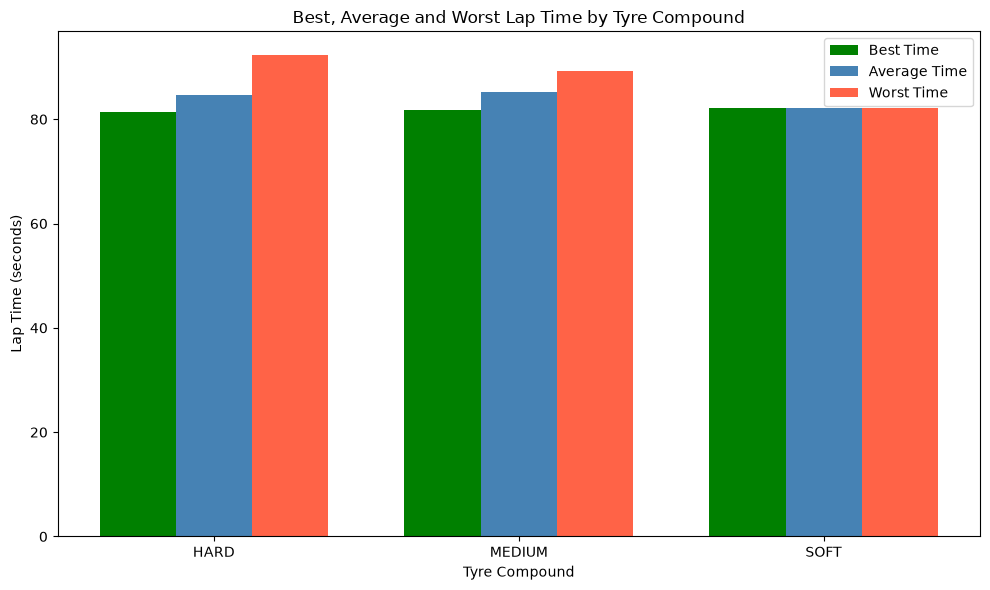

In [32]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(compound_summary))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width,
    compound_summary["BestLapTime"],
    width,
    label="Best Time",
    color="green",
)

ax.bar(
    x,
    compound_summary["AverageLapTime"],
    width,
    label="Average Time",
    color="steelblue"
)

ax.bar(
    x + width,
    compound_summary["SlowestLapTime"],
    width,
    label="Worst Time",
    color="tomato"
)

ax.set_title("Best, Average and Worst Lap Time by Tyre Compound")
ax.set_xlabel("Tyre Compound")
ax.set_ylabel("Lap Time (seconds)")
ax.set_xticks(x)
ax.set_xticklabels(compound_summary["Compound"])
ax.legend()

plt.tight_layout()
plt.show()